# Telco Customer Churn: Statistical Profiling, EDA and Naive Baseline

**Prepared by: Zaid**

This notebook profiles the Telco Customer Churn dataset, explores how features relate to churn, and sets a majority-class baseline before any real model is built.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"No": "#3b82a0", "Yes": "#e4572e"}

DATA_FILE = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
if not os.path.exists(DATA_FILE):
    from google.colab import files
    uploaded = files.upload()
    DATA_FILE = list(uploaded.keys())[0]
print("Using file:", DATA_FILE)

Using file: WA_Fn-UseC_-Telco-Customer-Churn.csv


## 1. Data loading and quality check

`TotalCharges` is expected to load as text because of blank strings. The cell below checks whether those blanks are random missing values or a known quirk.

In [2]:
df = pd.read_csv(DATA_FILE)
print("Shape:", df.shape)
print("Duplicate customerIDs:", df.customerID.duplicated().sum())
print("Raw dtype of TotalCharges:", df.TotalCharges.dtype)

blank_mask = df.TotalCharges.astype(str).str.strip() == ""
print("Blank-string TotalCharges rows:", int(blank_mask.sum()))
print("Tenure values for those rows:", sorted(df.loc[blank_mask, "tenure"].unique().tolist()))
print("Do all blank rows have tenure == 0?", bool((df.loc[blank_mask, "tenure"] == 0).all()))
print("Are all tenure == 0 rows blank?", bool(blank_mask.sum() == (df.tenure == 0).sum()))

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(), errors="coerce")
df.loc[df["tenure"] == 0, "TotalCharges"] = 0.0
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)
print("Missing values after fix:", int(df.drop(columns=["ChurnFlag"]).isna().sum().sum()))

print("\nColumns where 'No internet service' / 'No phone service' is its own level:")
for c in df.select_dtypes(include=["object", "string"]).columns:
    levels = df[c].unique().tolist()
    if any("No internet service" in str(v) or "No phone service" in str(v) for v in levels):
        print(" ", c, levels)

Shape: (7043, 21)
Duplicate customerIDs: 0
Raw dtype of TotalCharges: str
Blank-string TotalCharges rows: 11
Tenure values for those rows: [0]
Do all blank rows have tenure == 0? True
Are all tenure == 0 rows blank? True
Missing values after fix: 0

Columns where 'No internet service' / 'No phone service' is its own level:
  MultipleLines ['No phone service', 'No', 'Yes']
  OnlineSecurity ['No', 'Yes', 'No internet service']
  OnlineBackup ['Yes', 'No', 'No internet service']
  DeviceProtection ['No', 'Yes', 'No internet service']
  TechSupport ['No', 'Yes', 'No internet service']
  StreamingTV ['No', 'Yes', 'No internet service']
  StreamingMovies ['No', 'Yes', 'No internet service']


**What this shows.** All 11 blank `TotalCharges` rows belong to customers with `tenure = 0`, and every `tenure = 0` customer is blank. This is a known data-type quirk (new customers who have not been billed yet), not random missingness, so the blanks were converted to numbers and set to 0. No other column has missing values. Columns such as `OnlineSecurity` use "No internet service" as a real category, not as missing data.

## 2. Summary statistics for numerical columns

In [3]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
summary = df[num_cols].describe().T
summary["median"] = df[num_cols].median()
summary["variance"] = df[num_cols].var()
summary["skewness"] = df[num_cols].skew()
summary["kurtosis"] = df[num_cols].kurt()
summary["mean_minus_median"] = summary["mean"] - summary["median"]
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print(summary.round(3).to_string())

print("\nSkewness of TotalCharges before log1p:", round(float(df.TotalCharges.skew()), 3))
print("Skewness of TotalCharges after  log1p:", round(float(np.log1p(df.TotalCharges).skew()), 3))
print("Share of senior citizens:", round(df.SeniorCitizen.mean() * 100, 2), "%")
print("Share with tenure <= 6 months:", round((df.tenure <= 6).mean() * 100, 2), "%")
print("Share with tenure >= 66 months:", round((df.tenure >= 66).mean() * 100, 2), "%")
print("Customers paying between 18 and 25 per month:", int(((df.MonthlyCharges >= 18) & (df.MonthlyCharges <= 25)).sum()))

                 count      mean       std    min     25%      50%      75%      max   median     variance  skewness  kurtosis  mean_minus_median
tenure          7043.0    32.371    24.559   0.00    9.00    29.00    55.00    72.00    29.00      603.168     0.240    -1.387              3.371
MonthlyCharges  7043.0    64.762    30.090  18.25   35.50    70.35    89.85   118.75    70.35      905.411    -0.221    -1.257             -5.588
TotalCharges    7043.0  2279.734  2266.794   0.00  398.55  1394.55  3786.60  8684.80  1394.55  5138357.168     0.963    -0.229            885.184
SeniorCitizen   7043.0     0.162     0.369   0.00    0.00     0.00     0.00     1.00     0.00        0.136     1.834     1.363              0.162

Skewness of TotalCharges before log1p: 0.963
Skewness of TotalCharges after  log1p: -0.824
Share of senior citizens: 16.21 %
Share with tenure <= 6 months: 21.03 %
Share with tenure >= 66 months: 14.67 %
Customers paying between 18 and 25 per month: 1406


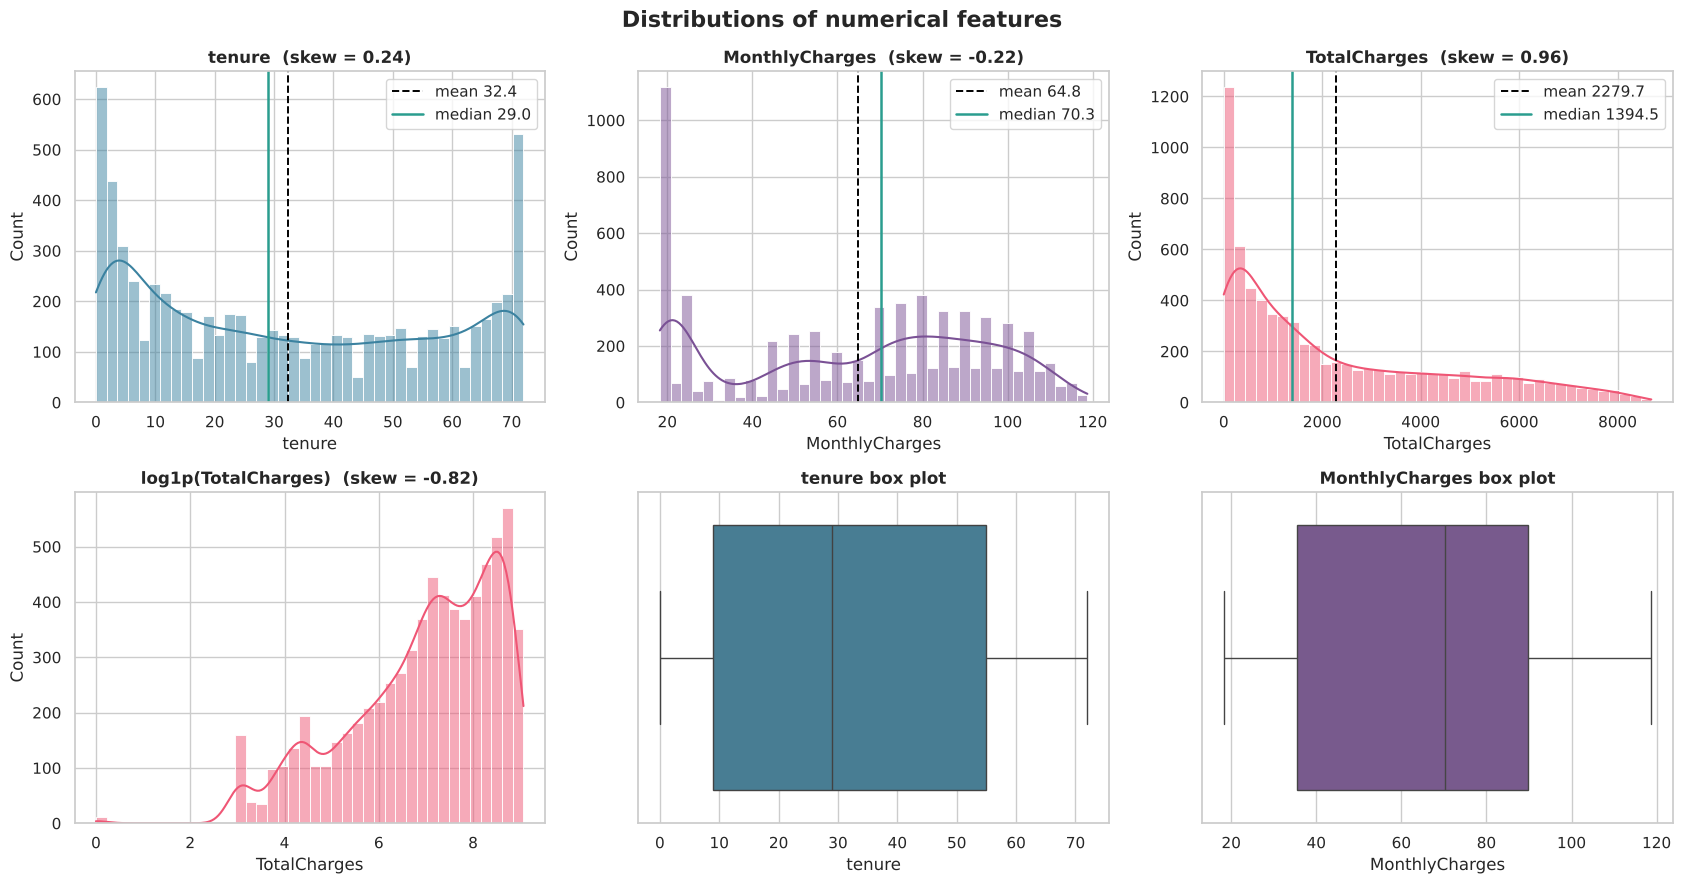

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col, colour in zip(axes[0], ["tenure", "MonthlyCharges", "TotalCharges"], ["#3b82a0", "#7a5195", "#ef5675"]):
    sns.histplot(df[col], bins=40, kde=True, color=colour, ax=ax, edgecolor="white")
    ax.axvline(df[col].mean(), color="black", linestyle="--", linewidth=1.4, label=f"mean {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color="#2a9d8f", linestyle="-", linewidth=1.8, label=f"median {df[col].median():.1f}")
    ax.set_title(f"{col}  (skew = {df[col].skew():.2f})", fontweight="bold")
    ax.legend()
sns.histplot(np.log1p(df["TotalCharges"]), bins=40, kde=True, color="#ef5675", ax=axes[1][0], edgecolor="white")
axes[1][0].set_title(f"log1p(TotalCharges)  (skew = {np.log1p(df['TotalCharges']).skew():.2f})", fontweight="bold")
for ax, col, colour in zip(axes[1][1:], ["tenure", "MonthlyCharges"], ["#3b82a0", "#7a5195"]):
    sns.boxplot(x=df[col], color=colour, ax=ax)
    ax.set_title(f"{col} box plot", fontweight="bold")
fig.suptitle("Distributions of numerical features", fontsize=16, fontweight="bold")
fig.tight_layout()
plt.show()

**Skewed distributions and their implication.**

1. **TotalCharges is right-skewed (skewness 0.96).** The mean (2,279.73) sits about 885 above the median (1,394.55) because a long tail of long-tenure, high-bill customers pulls it up. The mean overstates what a typical customer has paid, so the median is the better summary. A `log1p` transform removes the right skew (it overshoots to -0.82, so it is a partial fix), and linear or distance-based models later should use a transformed or scaled version.
2. **SeniorCitizen is heavily skewed (skewness 1.83).** It is a 0/1 flag, so this simply reflects that only 16.2% of customers are senior citizens. The mean is just that share and the median is 0. Any pattern found for seniors rests on a much smaller group than for non-seniors.

Two more columns need a warning even though their skewness coefficient is small. `tenure` (skew 0.24) is U-shaped, with 21.0% of customers at 6 months or less and 14.7% at 66 months or more, so its mean of 32.4 describes almost nobody. `MonthlyCharges` (skew -0.22) is bimodal, with about 1,400 customers paying roughly 18 to 25 and a second wide hump around 70 to 100, which a low skewness number hides.

## 3. Target distribution

       count  percent
Churn                
No      5174    73.46
Yes     1869    26.54
Imbalance ratio (No : Yes): 2.77 : 1


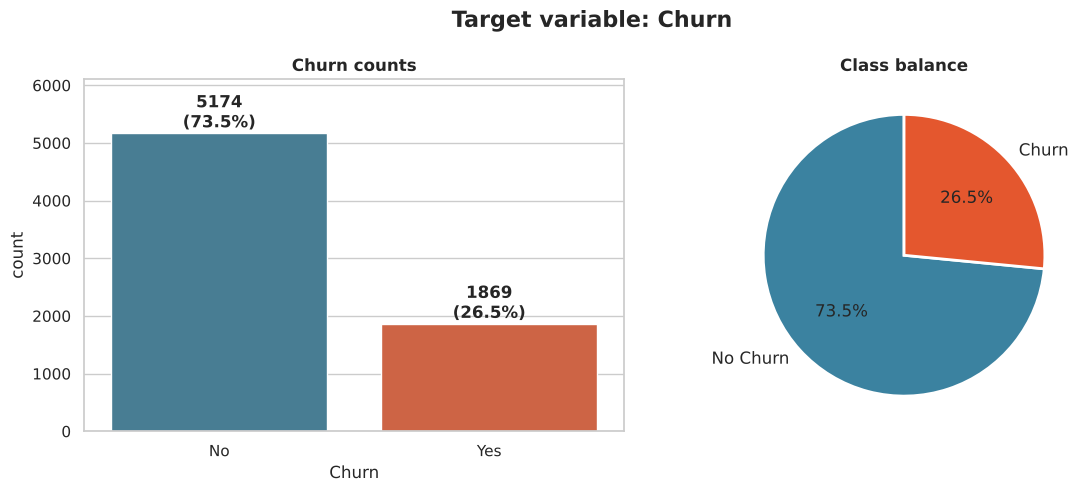

In [5]:
counts = df["Churn"].value_counts()
pct = df["Churn"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percent": pct.round(2)}).to_string())
print("Imbalance ratio (No : Yes):", round(float(counts["No"] / counts["Yes"]), 2), ": 1")

order = ["No", "Yes"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(data=df, x="Churn", order=order, palette=PALETTE, ax=axes[0])
for p, label in zip(axes[0].patches, order):
    axes[0].annotate(f"{int(p.get_height())}\n({pct[label]:.1f}%)", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=12, fontweight="bold")
axes[0].set_ylim(0, counts.max() * 1.18)
axes[0].set_title("Churn counts", fontweight="bold")
axes[1].pie([counts["No"], counts["Yes"]], labels=["No Churn", "Churn"], colors=[PALETTE["No"], PALETTE["Yes"]], autopct="%1.1f%%", startangle=90, wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 12})
axes[1].set_title("Class balance", fontweight="bold")
fig.suptitle("Target variable: Churn", fontsize=16, fontweight="bold")
fig.tight_layout()
plt.show()

**Interpretation.** 73.46% of customers did not churn (5,174) and 26.54% did (1,869), an imbalance of about 2.77 to 1. This is moderate imbalance. It means accuracy will be inflated by the majority class, so later models should be judged on precision, recall and F1 for the churn class, plus PR-AUC or ROC-AUC, with stratified train/test splits.

## 4. Bivariate analysis: features vs churn

### 4.1 Contract type vs churn

                customers  churners  churn_rate
Contract                                       
Month-to-month       3875      1655       42.71
One year             1473       166       11.27
Two year             1695        48        2.83


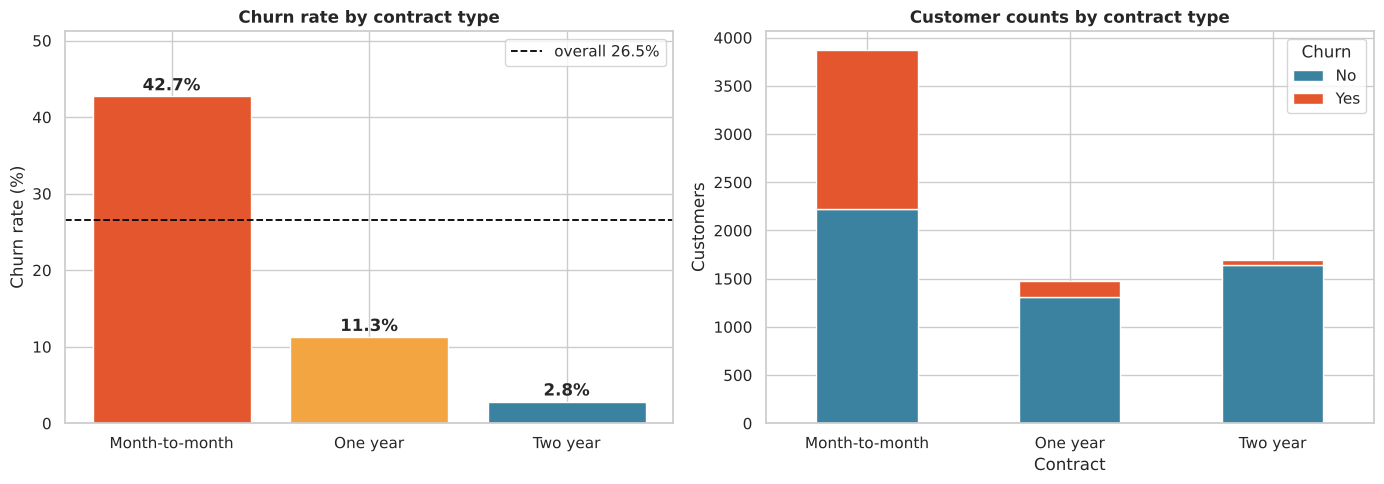

In [6]:
overall_rate = df["ChurnFlag"].mean() * 100
contract_tbl = df.groupby("Contract").agg(customers=("ChurnFlag", "size"), churners=("ChurnFlag", "sum"), churn_rate=("ChurnFlag", "mean"))
contract_tbl["churn_rate"] = contract_tbl["churn_rate"] * 100
contract_tbl = contract_tbl.loc[["Month-to-month", "One year", "Two year"]]
print(contract_tbl.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bars = axes[0].bar(contract_tbl.index, contract_tbl["churn_rate"], color=["#e4572e", "#f2a541", "#3b82a0"], edgecolor="white")
for b, v in zip(bars, contract_tbl["churn_rate"]):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.1f}%", ha="center", fontweight="bold")
axes[0].axhline(overall_rate, color="black", linestyle="--", linewidth=1.3, label=f"overall {overall_rate:.1f}%")
axes[0].set_ylabel("Churn rate (%)")
axes[0].set_ylim(0, contract_tbl["churn_rate"].max() * 1.2)
axes[0].set_title("Churn rate by contract type", fontweight="bold")
axes[0].legend()
ct = pd.crosstab(df["Contract"], df["Churn"]).loc[["Month-to-month", "One year", "Two year"]]
ct.plot(kind="bar", stacked=True, color=[PALETTE["No"], PALETTE["Yes"]], ax=axes[1], edgecolor="white")
axes[1].set_title("Customer counts by contract type", fontweight="bold")
axes[1].set_ylabel("Customers")
axes[1].tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()

**Interpretation.** Month-to-month customers churn at 42.71%, against 11.27% for one-year and 2.83% for two-year contracts, roughly 15 times the two-year rate and far above the overall 26.5%. They also make up 55% of the customer base, so this one segment holds 1,655 of the 1,869 churners (about 89%). The pattern is monotonic: the longer the commitment, the lower the churn. This is an association, not proof that contracts cause retention, because customers who already intend to stay are probably the ones who choose longer contracts.

### 4.2 Tenure vs churn

        mean  median    std
Churn                      
No     37.57    38.0  24.11
Yes    17.98    10.0  19.53
            customers  churn_rate
TenureBand                       
0-6              1481       52.94
7-12              705       35.89
13-24            1024       28.71
25-48            1594       20.39
49-60             832       14.42
61-72            1407        6.61


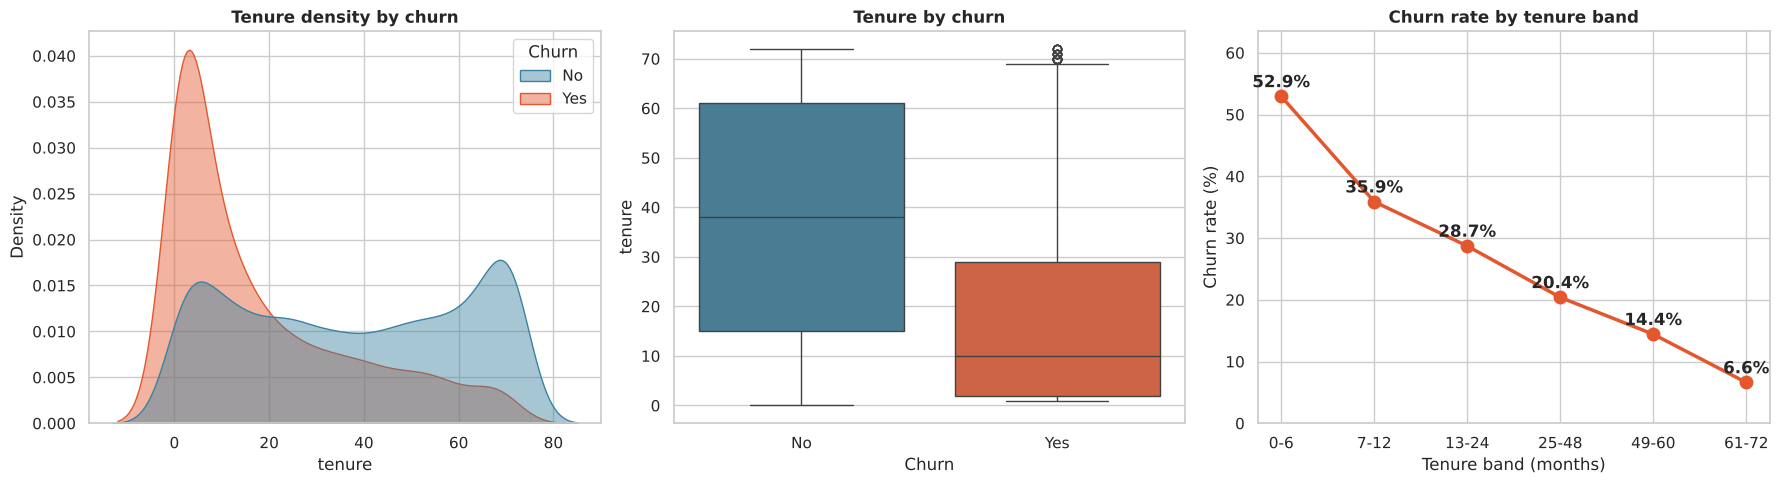

In [7]:
tenure_stats = df.groupby("Churn")["tenure"].agg(["mean", "median", "std"])
print(tenure_stats.round(2).to_string())

bins = [-1, 6, 12, 24, 48, 60, 72]
labels = ["0-6", "7-12", "13-24", "25-48", "49-60", "61-72"]
df["TenureBand"] = pd.cut(df["tenure"], bins=bins, labels=labels)
tenure_tbl = df.groupby("TenureBand", observed=True).agg(customers=("ChurnFlag", "size"), churn_rate=("ChurnFlag", "mean"))
tenure_tbl["churn_rate"] = tenure_tbl["churn_rate"] * 100
print(tenure_tbl.round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.kdeplot(data=df, x="tenure", hue="Churn", fill=True, common_norm=False, palette=PALETTE, alpha=0.45, ax=axes[0])
axes[0].set_title("Tenure density by churn", fontweight="bold")
sns.boxplot(data=df, x="Churn", y="tenure", order=order, palette=PALETTE, ax=axes[1])
axes[1].set_title("Tenure by churn", fontweight="bold")
axes[2].plot(tenure_tbl.index.astype(str), tenure_tbl["churn_rate"], marker="o", color="#e4572e", linewidth=2.5, markersize=9)
for x, v in zip(tenure_tbl.index.astype(str), tenure_tbl["churn_rate"]):
    axes[2].text(x, v + 1.5, f"{v:.1f}%", ha="center", fontweight="bold")
axes[2].set_ylim(0, tenure_tbl["churn_rate"].max() * 1.2)
axes[2].set_xlabel("Tenure band (months)")
axes[2].set_ylabel("Churn rate (%)")
axes[2].set_title("Churn rate by tenure band", fontweight="bold")
fig.tight_layout()
plt.show()

**Interpretation.** Churners have a mean tenure of 17.98 months and a median of only 10, against a mean of 37.57 and a median of 38 for customers who stayed. Churn falls steadily with tenure, from 52.94% in the first six months to 6.61% after five years, so the first year is clearly the danger zone. One caution is survivorship: the long-tenure group only contains people who did not leave earlier, so part of the low late churn is a selection effect and not purely loyalty growing over time.

### 4.3 Monthly charges vs churn

        mean  median    std
Churn                      
No     61.27   64.43  31.09
Yes    74.44   79.65  24.67
            customers  churn_rate
ChargeBand                       
<=30             1653        9.80
30-50             646       30.80
50-70            1161       20.76
70-90            1844       37.80
90+              1739       32.78

Share of customers paying 30 or less who have no internet service: 92.3 %
Average MonthlyCharges by InternetService:
InternetService
DSL            58.1
Fiber optic    91.5
No             21.1


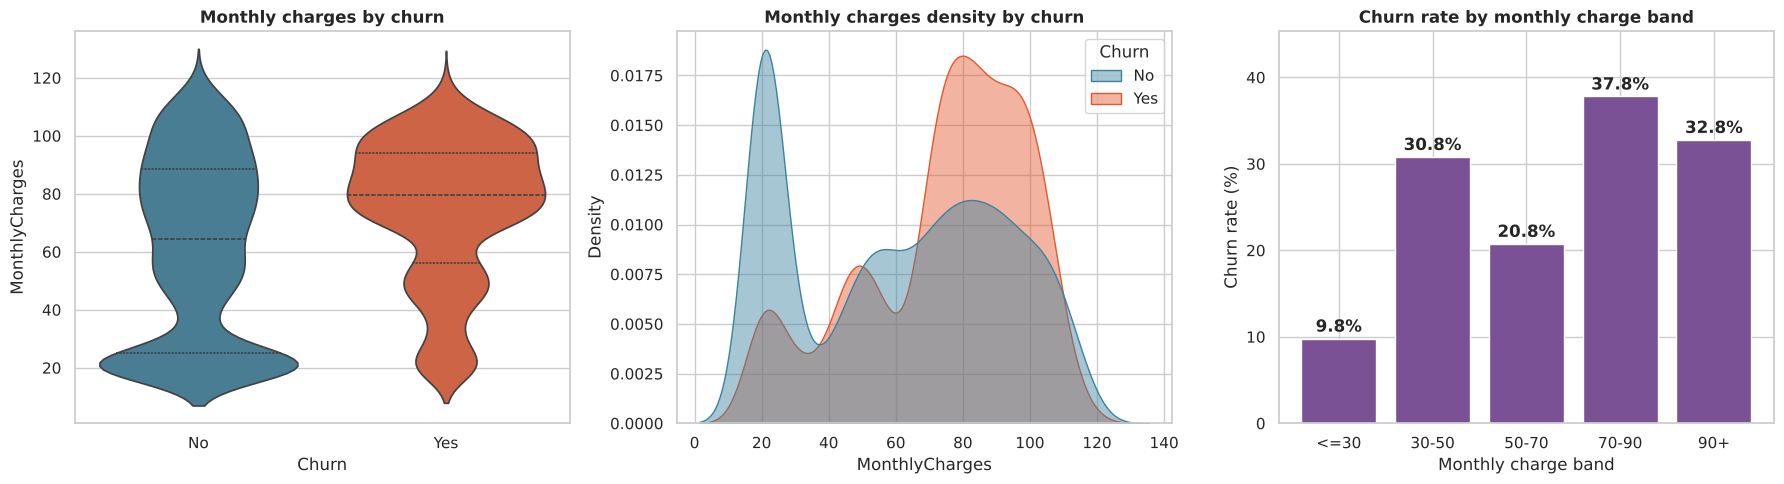

In [8]:
mc_stats = df.groupby("Churn")["MonthlyCharges"].agg(["mean", "median", "std"])
print(mc_stats.round(2).to_string())

mc_bins = [0, 30, 50, 70, 90, 120]
mc_labels = ["<=30", "30-50", "50-70", "70-90", "90+"]
df["ChargeBand"] = pd.cut(df["MonthlyCharges"], bins=mc_bins, labels=mc_labels)
mc_tbl = df.groupby("ChargeBand", observed=True).agg(customers=("ChurnFlag", "size"), churn_rate=("ChurnFlag", "mean"))
mc_tbl["churn_rate"] = mc_tbl["churn_rate"] * 100
print(mc_tbl.round(2).to_string())

low = df[df.MonthlyCharges <= 30]
print("\nShare of customers paying 30 or less who have no internet service:", round((low.InternetService == "No").mean() * 100, 1), "%")
print("Average MonthlyCharges by InternetService:")
print(df.groupby("InternetService")["MonthlyCharges"].mean().round(1).to_string())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.violinplot(data=df, x="Churn", y="MonthlyCharges", order=order, palette=PALETTE, inner="quartile", ax=axes[0])
axes[0].set_title("Monthly charges by churn", fontweight="bold")
sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", fill=True, common_norm=False, palette=PALETTE, alpha=0.45, ax=axes[1])
axes[1].set_title("Monthly charges density by churn", fontweight="bold")
axes[2].bar(mc_tbl.index.astype(str), mc_tbl["churn_rate"], color="#7a5195", edgecolor="white")
for x, v in zip(mc_tbl.index.astype(str), mc_tbl["churn_rate"]):
    axes[2].text(x, v + 0.8, f"{v:.1f}%", ha="center", fontweight="bold")
axes[2].set_ylim(0, mc_tbl["churn_rate"].max() * 1.2)
axes[2].set_xlabel("Monthly charge band")
axes[2].set_ylabel("Churn rate (%)")
axes[2].set_title("Churn rate by monthly charge band", fontweight="bold")
fig.tight_layout()
plt.show()

**Interpretation.** Churners pay more on average (mean 74.44, median 79.65) than customers who stayed (mean 61.27, median 64.43). The relationship is not a clean straight line: the cheapest band churns least (9.80%), the 70 to 90 band churns most (37.80%), and the 50 to 70 band dips in between (20.76%). Of the customers paying 30 or less, 92% have no internet service (phone-only), a group that churns at only 7.40%, while fiber optic customers pay about 91.5 per month on average and have the highest churn rate in the data. So the price effect is tangled up with service type and contract, and this chart alone cannot say that price itself drives people away.

### 4.4 Extra views: internet service and payment method

InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24


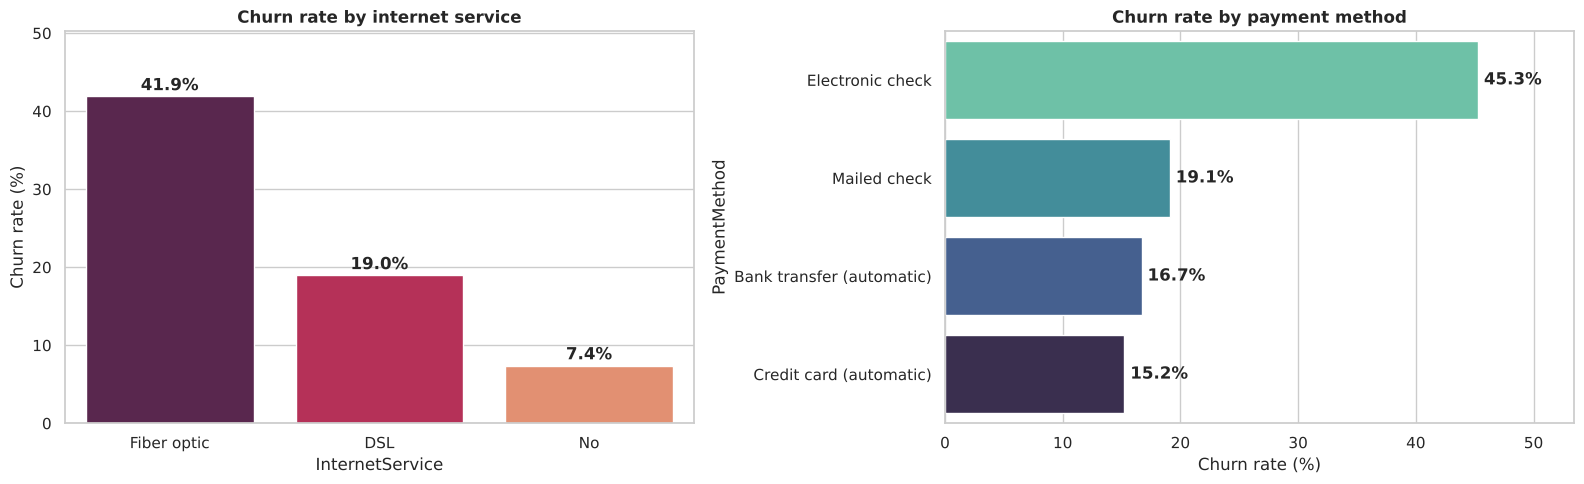

In [9]:
inet_tbl = df.groupby("InternetService")["ChurnFlag"].mean().mul(100).sort_values(ascending=False)
pay_tbl = df.groupby("PaymentMethod")["ChurnFlag"].mean().mul(100).sort_values(ascending=False)
print(inet_tbl.round(2).to_string())
print(pay_tbl.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=inet_tbl.index, y=inet_tbl.values, palette="rocket", ax=axes[0])
for i, v in enumerate(inet_tbl.values):
    axes[0].text(i, v + 0.8, f"{v:.1f}%", ha="center", fontweight="bold")
axes[0].set_ylim(0, inet_tbl.max() * 1.2)
axes[0].set_ylabel("Churn rate (%)")
axes[0].set_title("Churn rate by internet service", fontweight="bold")
sns.barplot(y=pay_tbl.index, x=pay_tbl.values, palette="mako_r", ax=axes[1], orient="h")
for i, v in enumerate(pay_tbl.values):
    axes[1].text(v + 0.5, i, f"{v:.1f}%", va="center", fontweight="bold")
axes[1].set_xlim(0, pay_tbl.max() * 1.18)
axes[1].set_xlabel("Churn rate (%)")
axes[1].set_title("Churn rate by payment method", fontweight="bold")
fig.tight_layout()
plt.show()

**Interpretation.** Electronic check users churn at 45.29%, compared with 15.24% to 19.11% for the other three payment methods, and fiber optic customers churn at 41.89% against 18.96% for DSL and 7.40% for no internet. Both are worth carrying into later modeling, with the same caution that they overlap with contract type and tenure.

## 5. Correlation heatmap for numerical features

                tenure  MonthlyCharges  TotalCharges  SeniorCitizen  Churn (0/1)
tenure           1.000           0.248         0.826          0.017       -0.352
MonthlyCharges   0.248           1.000         0.651          0.220        0.193
TotalCharges     0.826           0.651         1.000          0.103       -0.198
SeniorCitizen    0.017           0.220         0.103          1.000        0.151
Churn (0/1)     -0.352           0.193        -0.198          0.151        1.000

corr(TotalCharges, tenure * MonthlyCharges): 0.9996
Share of customers within 10% of tenure * MonthlyCharges: 94.43 %

Pairs ranked by absolute correlation:
           tenure vs TotalCharges    +0.826
   MonthlyCharges vs TotalCharges    +0.651
           tenure vs Churn (0/1)     -0.352
           tenure vs MonthlyCharges  +0.248
   MonthlyCharges vs SeniorCitizen   +0.220
     TotalCharges vs Churn (0/1)     -0.198
   MonthlyCharges vs Churn (0/1)     +0.193
    SeniorCitizen vs Churn (0/1)     +0.151
    

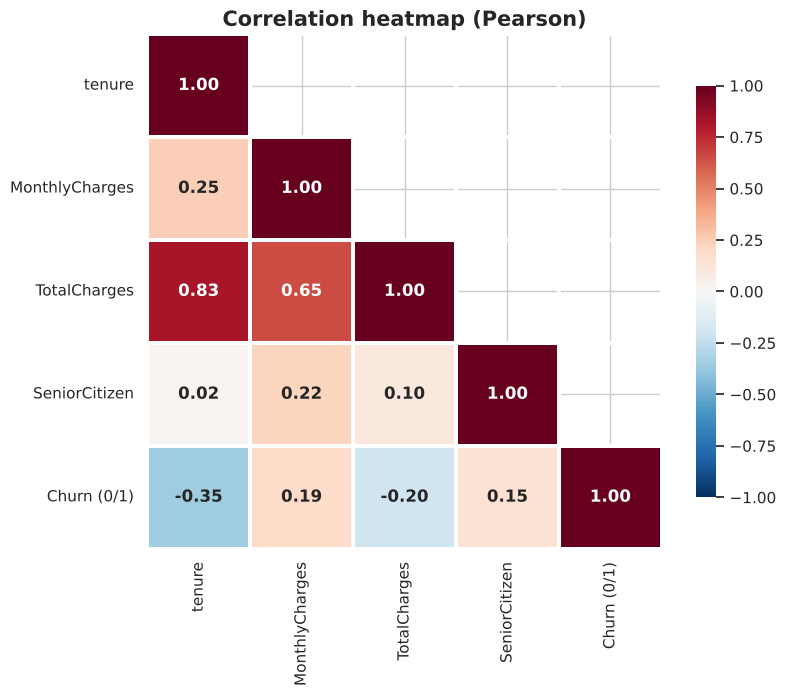

In [10]:
corr_df = df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "ChurnFlag"]].rename(columns={"ChurnFlag": "Churn (0/1)"})
corr = corr_df.corr(method="pearson")
print(corr.round(3).to_string())

df["ExpectedTotal"] = df["tenure"] * df["MonthlyCharges"]
rel_gap = (df["TotalCharges"] - df["ExpectedTotal"]).abs() / df["ExpectedTotal"].replace(0, np.nan)
print("\ncorr(TotalCharges, tenure * MonthlyCharges):", round(float(df["TotalCharges"].corr(df["ExpectedTotal"])), 4))
print("Share of customers within 10% of tenure * MonthlyCharges:", round(float((rel_gap <= 0.10).mean()) * 100, 2), "%")

pairs = []
names = corr.columns.tolist()
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        pairs.append((names[i], names[j], corr.iloc[i, j]))
pairs.sort(key=lambda t: -abs(t[2]))
print("\nPairs ranked by absolute correlation:")
for a, b, v in pairs:
    print(f"  {a:>15} vs {b:<15} {v:+.3f}")

fig, ax = plt.subplots(figsize=(8.5, 7))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=1.5, linecolor="white", mask=mask, cbar_kws={"shrink": 0.8}, annot_kws={"fontsize": 12, "fontweight": "bold"}, ax=ax)
ax.set_title("Correlation heatmap (Pearson)", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

**Flags.**

- **Strongest relationship:** `tenure` vs `TotalCharges` (+0.83), followed by `MonthlyCharges` vs `TotalCharges` (+0.65). This is not a surprise once checked, because `TotalCharges` is almost a derived column: its correlation with `tenure x MonthlyCharges` is 0.9996, and 94.4% of customers sit within 10% of that product. It is a near-duplicate feature that matters for feature engineering and for multicollinearity in linear models.
- **Surprising sign flip:** `MonthlyCharges` correlates positively with churn (+0.19) while `TotalCharges` correlates negatively (-0.20). Both are driven by tenure: high monthly bills go with more churn, but a high cumulative total simply means the customer stayed a long time.
- **Weakest:** `tenure` and `SeniorCitizen` are essentially uncorrelated (+0.02), and senior status has only a modest link to churn (+0.15). The strongest link to churn is `tenure` (-0.35), which is moderate at best.
- **Limits:** Pearson only measures linear association, so it understates the non-monotonic `MonthlyCharges` pattern seen earlier, correlations with a 0/1 target are compressed, and none of this says anything about causation.

## 6. Majority-class baseline

Predicted classes present: [0]
Confusion matrix [[TN, FP], [FN, TP]]:
[[5174    0]
 [1869    0]]
Accuracy          : 0.7346
Precision (churn) : 0.0000
Recall    (churn) : 0.0000
F1        (churn) : 0.0000
Churners caught: 0 of 1869

Contrast, always predict Churn:
Accuracy 0.2654 | Precision 0.2654 | Recall 1.0000 | F1 0.4194


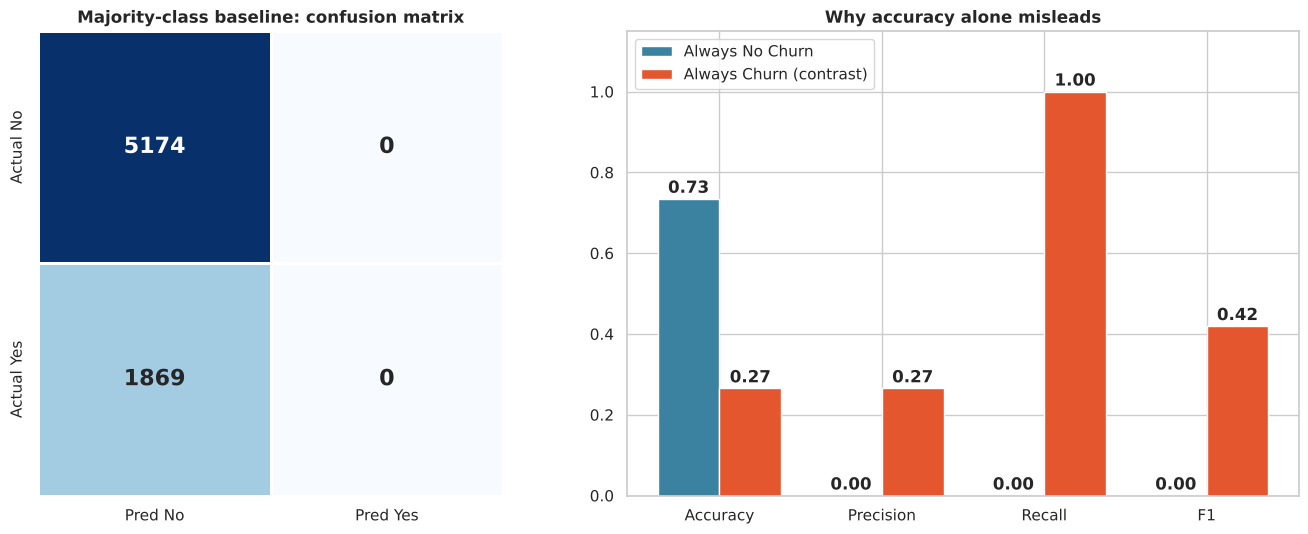

In [11]:
X = df.drop(columns=["Churn", "ChurnFlag", "customerID", "TenureBand", "ChargeBand", "ExpectedTotal"])
y = df["ChurnFlag"]

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X, y)
pred = dummy.predict(X)

acc = accuracy_score(y, pred)
prec = precision_score(y, pred, pos_label=1, zero_division=0)
rec = recall_score(y, pred, pos_label=1, zero_division=0)
f1 = f1_score(y, pred, pos_label=1, zero_division=0)
cm = confusion_matrix(y, pred, labels=[0, 1])

print("Predicted classes present:", np.unique(pred).tolist())
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm)
print(f"Accuracy          : {acc:.4f}")
print(f"Precision (churn) : {prec:.4f}")
print(f"Recall    (churn) : {rec:.4f}")
print(f"F1        (churn) : {f1:.4f}")
print("Churners caught:", int(cm[1, 1]), "of", int(cm[1].sum()))

always_yes = np.ones_like(y)
ay = [accuracy_score(y, always_yes), precision_score(y, always_yes, zero_division=0), recall_score(y, always_yes, zero_division=0), f1_score(y, always_yes, zero_division=0)]
print("\nContrast, always predict Churn:")
print(f"Accuracy {ay[0]:.4f} | Precision {ay[1]:.4f} | Recall {ay[2]:.4f} | F1 {ay[3]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True, linewidths=2, linecolor="white", xticklabels=["Pred No", "Pred Yes"], yticklabels=["Actual No", "Actual Yes"], annot_kws={"fontsize": 16, "fontweight": "bold"}, ax=axes[0])
axes[0].set_title("Majority-class baseline: confusion matrix", fontweight="bold")
metric_names = ["Accuracy", "Precision", "Recall", "F1"]
x = np.arange(len(metric_names))
w = 0.38
b1 = axes[1].bar(x - w / 2, [acc, prec, rec, f1], w, label="Always No Churn", color="#3b82a0", edgecolor="white")
b2 = axes[1].bar(x + w / 2, ay, w, label="Always Churn (contrast)", color="#e4572e", edgecolor="white")
for bars in (b1, b2):
    for b in bars:
        axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.015, f"{b.get_height():.2f}", ha="center", fontweight="bold")
axes[1].set_xticks(x)
axes[1].set_xticklabels(metric_names)
axes[1].set_ylim(0, 1.15)
axes[1].set_title("Why accuracy alone misleads", fontweight="bold")
axes[1].legend()
fig.tight_layout()
plt.show()

**Interpretation.** The baseline always predicts "No Churn", so it scores 73.46% accuracy simply because 73.46% of customers do not churn, yet its precision, recall and F1 for the churn class are all 0.00 and it catches 0 of 1,869 churners. Accuracy rewards getting the majority class right, so on imbalanced data a high number can hide a model that finds nobody who is about to leave. For contrast, always predicting "Churn" gets only 26.54% accuracy but a recall of 1.00 and an F1 of 0.42, which shows how much the choice of metric changes the ranking.

The baseline is still a meaningful reference point and not a joke: any real model must beat 73.46% accuracy and, more importantly, must reach a churn-class F1 well above 0.00 and above the 0.42 of blind guessing. A later model that reports about 75% accuracy is only about 1.5 points better than doing nothing, so its churn-class precision and recall must be checked before calling it good.

## 7. Key takeaways

- Churn is concentrated in new customers on month-to-month contracts who pay by electronic check, use fiber optic service and have higher monthly bills.
- Class imbalance (26.5% churn) means accuracy is not a safe headline metric.
- `TotalCharges` is largely redundant with `tenure` and `MonthlyCharges` and needs careful handling when modeling.
- Every finding here is an association from observational data and should not be read as causal.